<a href="https://colab.research.google.com/github/ReNZzyi/IT-and-Programming/blob/main/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 12. Визуализация и первичный анализ данных

ФИО студента: **Петров Данила Максимович**

Группа студента: **ИНБ-б-о-26-2**

Вариант: **14**

## Задание

Изучить представленный в учебном примере код, разобраться в вызовах функций и значениях параметров. Реализовать построение аналогичных графиков с использованием другого набора данных, скачанного из Интернета или взятого из практической работы №7.

**Вариант 14** - набор данных `p7_data_14.csv` из практической работы №7: сведения о 1000 товаров (ID, наименование, категория, количество, цена, признак просрочки, признак наличия скидки).

## Решение

### Подключение библиотек

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
%matplotlib inline

### Загрузка данных

In [ ]:
!wget https://raw.githubusercontent.com/enikolaev/IT-and-Programming/refs/heads/main/data/pract7/p7_data_14.csv

In [3]:
data_path = 'p7_data_14.csv'
data = pd.read_csv(data_path)
data.head(10)

,ID,Name,Category,Count,Price,OutOfDate,WithDiscount
0,1,"Fish - Atlantic Salmon, Cold",D,16,$60.49,True,True
1,2,Sauce - Cranberry,B,26,$19.52,True,True
2,3,Pan Grease,D,22,$20.87,NaN,True
3,4,Coffee Guatemala Dark,A,10,$31.81,NaN,True
4,5,Wine - Carmenere Casillero Del,NaN,22,$75.15,False,NaN
5,6,"Olives - Black, Pitted",NaN,5,$95.04,NaN,NaN
6,7,Tea Leaves - Oolong,B,17,$37.78,NaN,NaN
7,8,Wine - Prem Select Charddonany,A,7,$26.36,False,False
8,9,Corn Meal,C,15,$95.68,False,False
9,10,Ginger - Fresh,A,29,$70.55,False,NaN


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   ID            1000 non-null   int64 
 1   Name          1000 non-null   str   
 2   Category      792 non-null    str   
 3   Count         1000 non-null   int64 
 4   Price         1000 non-null   str   
 5   OutOfDate     834 non-null    object
 6   WithDiscount  746 non-null    object
dtypes: int64(2), object(2), str(3)
memory usage: 54.8+ KB


Из `info()` видно, что:
* `Price` прочитан как строка (`object`/`str`) из-за символа `$` - его нужно преобразовать в число;
* в `Category` 792 непустых значения из 1000 - у 208 товаров категория не указана;
* `OutOfDate` и `WithDiscount` - логические признаки с пропусками (тип `object`).

### Предобработка данных

In [5]:
data['Price'] = data['Price'].str.lstrip('$').astype(float)

data['Category'] = data['Category'].fillna('Нет')

flag_names = {True: 'Да', False: 'Нет'}
data['OutOfDate'] = data['OutOfDate'].map(flag_names).fillna('Нет данных')
data['WithDiscount'] = data['WithDiscount'].map(flag_names).fillna('Нет данных')

data['Total'] = data['Count'] * data['Price']
data['Name length'] = data['Name'].str.len()

data.head()

,ID,Name,Category,Count,Price,OutOfDate,WithDiscount,Total,Name length
0,1,"Fish - Atlantic Salmon, Cold",D,16,60.49,Да,Да,967.84,28
1,2,Sauce - Cranberry,B,26,19.52,Да,Да,507.52,17
2,3,Pan Grease,D,22,20.87,Нет данных,Да,459.14,10
3,4,Coffee Guatemala Dark,A,10,31.81,Нет данных,Да,318.10,21
4,5,Wine - Carmenere Casillero Del,Нет,22,75.15,Нет,Нет данных,1653.30,30


Метод `describe()` выводит основные статистики количественных признаков: количество, среднее, стандартное отклонение, минимум, квартили, максимум

In [6]:
data.describe().round(2)

,ID,Count,Price,Total,Name length
count,1000.00,1000.00,1000.00,1000.00,1000.00
mean,500.50,25.48,51.33,1320.56,20.65
std,288.82,14.57,28.10,1129.40,6.38
min,1.00,1.00,5.05,6.07,4.00
25%,250.75,13.00,26.37,397.40,16.00
50%,500.50,26.00,48.61,951.09,21.00
75%,750.25,38.00,76.45,2015.11,26.00
max,1000.00,50.00,99.86,4993.00,35.00


### Одиночные признаки
#### Количественные признаки

In [7]:
data.columns

Index(['ID', 'Name', 'Category', 'Count', 'Price', 'OutOfDate', 'WithDiscount',
       'Total', 'Name length'],
      dtype='str')

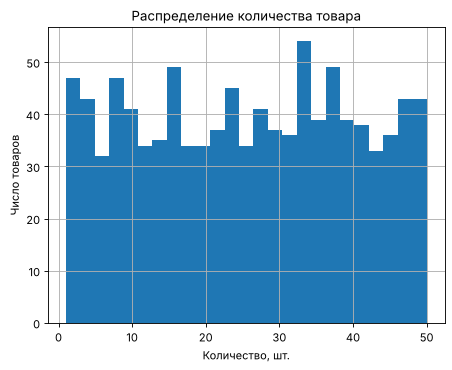

In [8]:
data['Count'].hist(bins=25)
plt.title('Распределение количества товара')
plt.xlabel('Количество, шт.')
plt.ylabel('Число товаров');

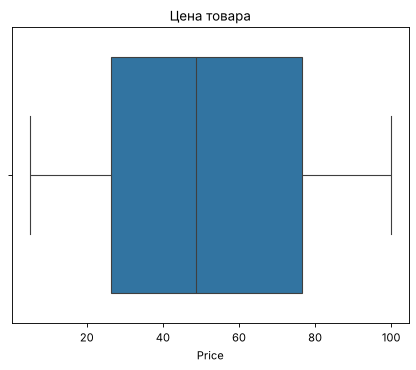

In [9]:
sns.boxplot(x=data['Price'])
plt.title('Цена товара');

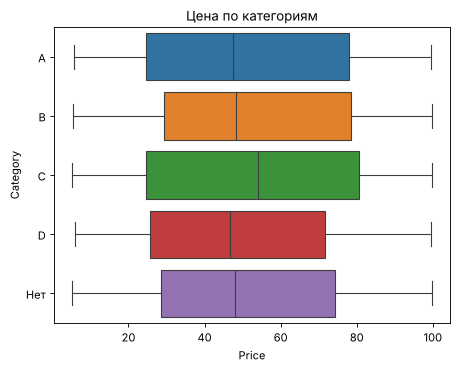

In [10]:
order = ['A', 'B', 'C', 'D', 'Нет']
sns.boxplot(y='Category', x='Price', data=data, order=order,
            hue='Category', hue_order=order)
plt.title('Цена по категориям');

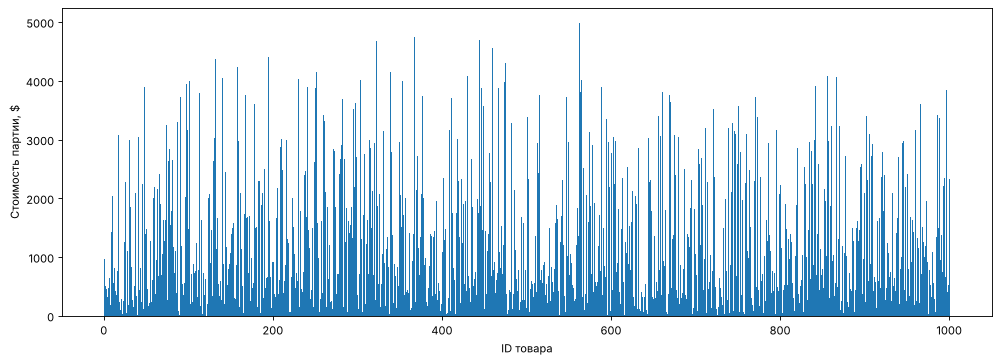

In [11]:
plt.figure(figsize=(15, 5))
plt.bar(data['ID'], data['Total'], width=1.0)
plt.xlabel('ID товара')
plt.ylabel('Стоимость партии, $')
plt.show()

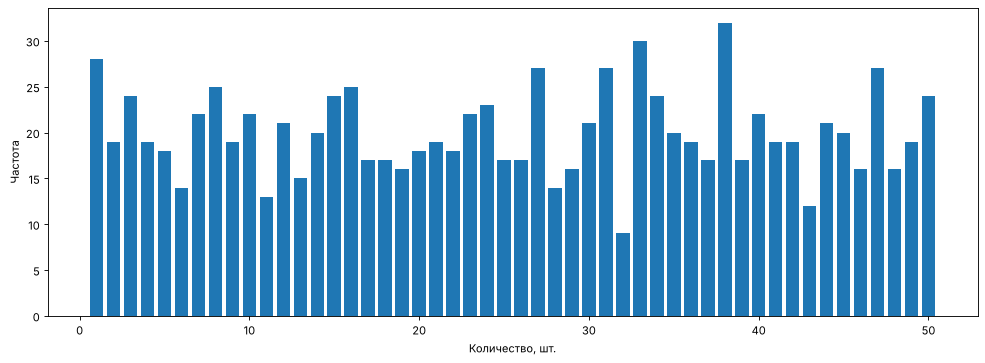

In [12]:
hist = data['Count'].value_counts().sort_index()
plt.figure(figsize=(15, 5))
plt.bar(hist.index, hist)
plt.xlabel('Количество, шт.')
plt.ylabel('Частота');

In [13]:
feats = ['Count', 'Price', 'Total', 'Name length']
feats

['Count', 'Price', 'Total', 'Name length']

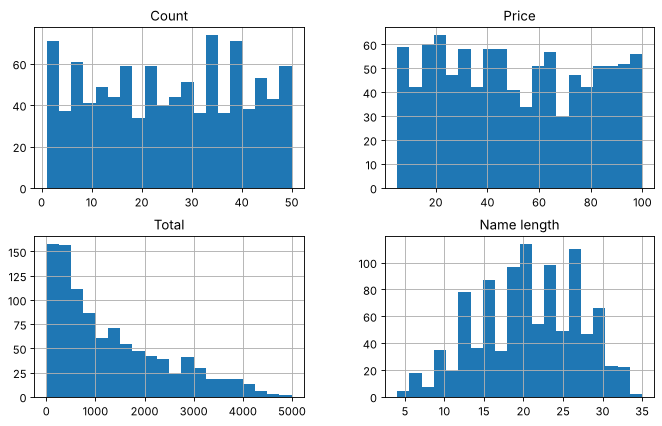

In [14]:
data[feats].hist(figsize=(10, 6), bins=20);

**Наблюдения.** Количество (1…50 шт.) и цена ($5…$100) распределены практически равномерно: столбцы гистограмм примерно одной высоты, медианы близки к серединам диапазонов. Это характерно для сгенерированных (учебных) данных. Стоимость партии `Total`, как произведение двух равномерных величин, распределена несимметрично: много дешёвых партий и «хвост» дорогих, до $4993. Выбросов на диаграммах размаха нет. Медианная цена в категориях отличается мало (от $46.8 в D до $54.0 в C).

### Категориальные признаки

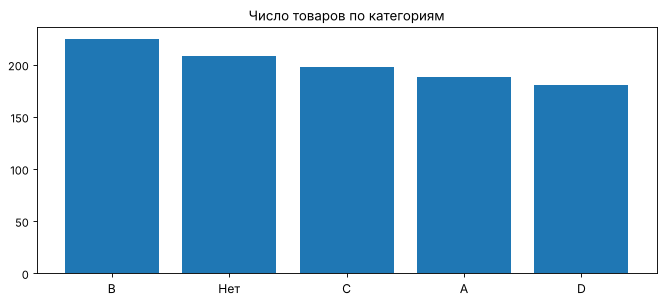

In [15]:
hist = data['Category'].value_counts()
f, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.bar(hist.index, hist)
ax.tick_params(axis='x', labelsize=11)
ax.set_title('Число товаров по категориям')
plt.show()

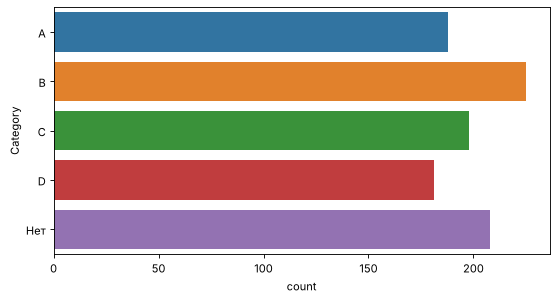

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(ax=ax, y='Category', data=data, order=order,
              hue='Category', hue_order=order);

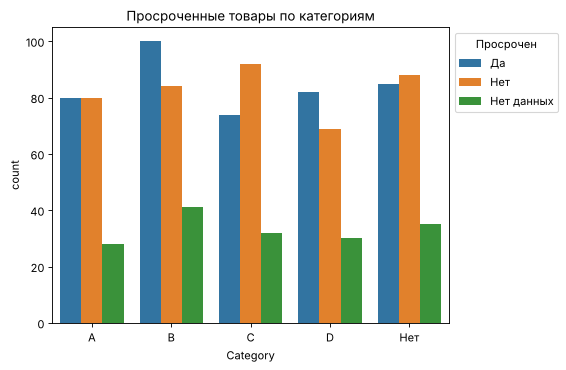

In [17]:
sns.countplot(x='Category', data=data, order=order,
              hue='OutOfDate', hue_order=['Да', 'Нет', 'Нет данных'])
plt.legend(title='Просрочен', loc='upper left', bbox_to_anchor=(1, 1))
plt.title('Просроченные товары по категориям');

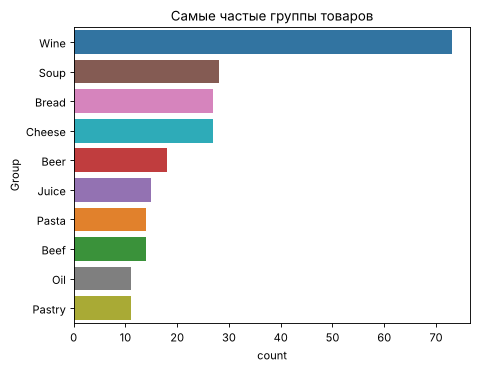

In [18]:
groups = data['Name'].str.split(' - ').str[0]
d1 = data[groups.isin(groups.value_counts().head(10).index)].assign(Group=groups)
sns.countplot(y='Group', data=d1, order=groups.value_counts().head(10).index,
              hue='Group', legend=False)
plt.title('Самые частые группы товаров');

**Наблюдения.** Категории сбалансированы: от 181 (D) до 225 (B) товаров, ещё 208 товаров без категории. Доли просроченных и непросроченных товаров в категориях близки. Среди наименований чаще всего встречаются вина (`Wine`, 73 позиции), далее с большим отрывом - `Soup`, `Bread`, `Cheese`, `Beer`.

### Взаимосвязанные признаки
#### Количественный – количественный

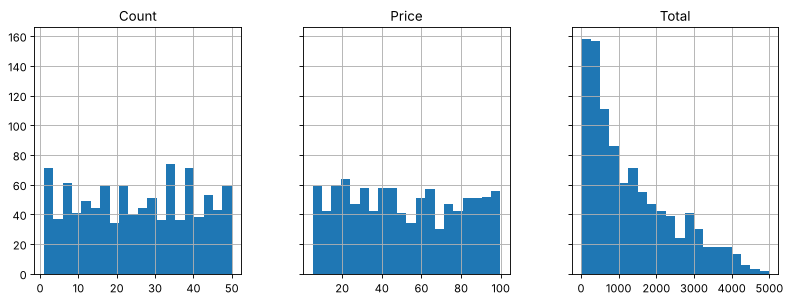

In [19]:
data[['Count', 'Price', 'Total']].hist(figsize=(12, 4), layout=(1, 3), sharey=True, bins=20);

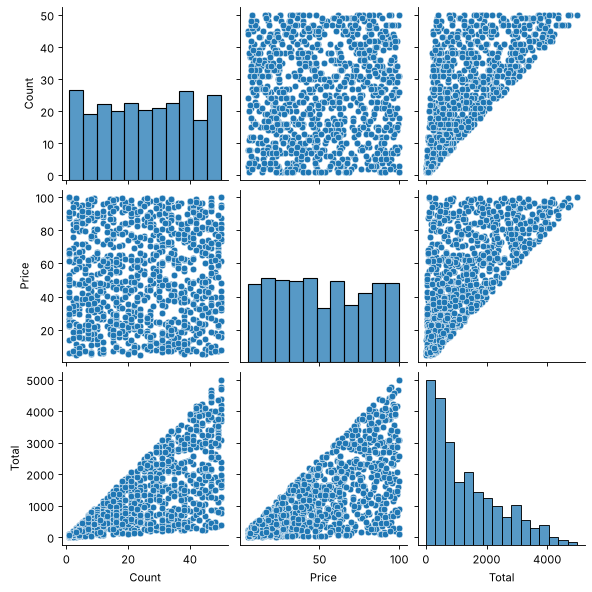

In [20]:
sns.pairplot(data[['Count', 'Price', 'Total']]);

Можно строить более сложные попарные распределения признаков - с раскраской по категориальному признаку

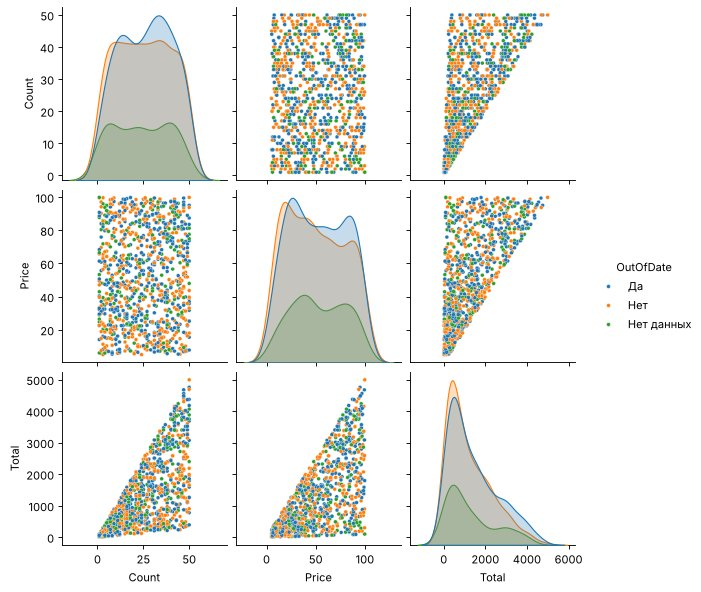

In [21]:
sns.pairplot(data[['Count', 'Price', 'Total', 'OutOfDate']], hue='OutOfDate',
             hue_order=['Да', 'Нет', 'Нет данных'], plot_kws={'s': 12});

Использование matplotlib, подписей данных, заголовков. Использование простейших пользовательских цветов

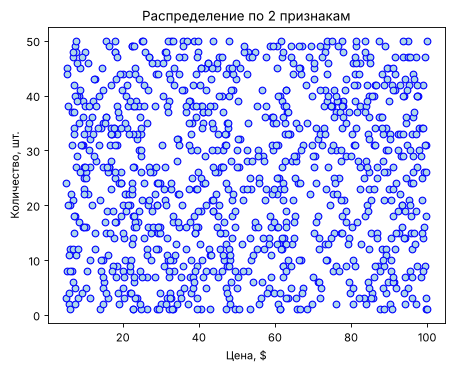

In [22]:
plt.scatter(data['Price'], data['Count'],
            color='lightblue', edgecolors='blue')
plt.xlabel('Цена, $')
plt.ylabel('Количество, шт.')
plt.title('Распределение по 2 признакам');

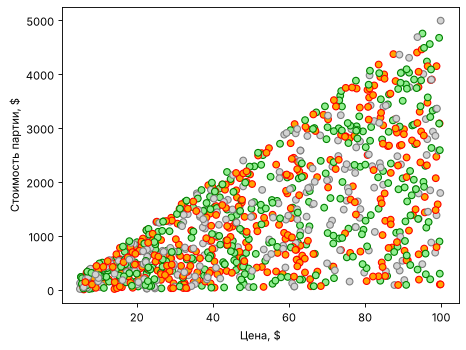

In [23]:
c = data['WithDiscount'].map({'Да': 'lightgreen', 'Нет': 'orange', 'Нет данных': 'lightgray'})
edge_c = data['WithDiscount'].map({'Да': 'green', 'Нет': 'red', 'Нет данных': 'gray'})
plt.scatter(data['Price'], data['Total'], color=c, edgecolors=edge_c)
plt.xlabel('Цена, $')
plt.ylabel('Стоимость партии, $');

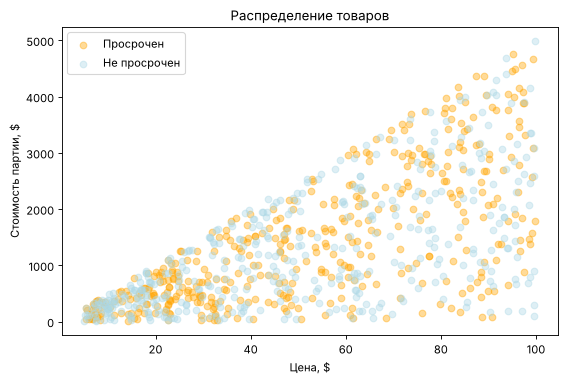

In [24]:
data_expired = data[data['OutOfDate'] == 'Да']
data_fresh = data[data['OutOfDate'] == 'Нет']

plt.figure(figsize=(8, 5))
plt.scatter(data_expired['Price'], data_expired['Total'],
            color='orange', alpha=0.4, label='Просрочен')
plt.scatter(data_fresh['Price'], data_fresh['Total'],
            color='lightblue', alpha=0.4, label='Не просрочен')
plt.xlabel('Цена, $')
plt.ylabel('Стоимость партии, $')
plt.title('Распределение товаров')
plt.legend();

#### Количественный – категориальный

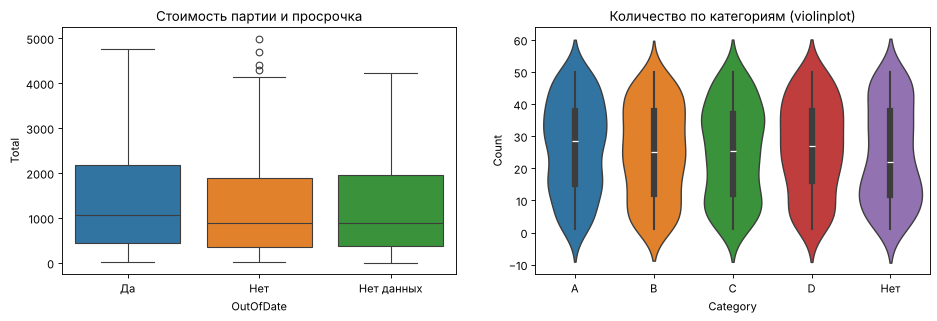

OutOfDate
Да            1073.28
Нет            895.95
Нет данных     891.79
Name: Total, dtype: float64


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(ax=axes[0], x='OutOfDate', y='Total', data=data,
            order=['Да', 'Нет', 'Нет данных'], hue='OutOfDate',
            hue_order=['Да', 'Нет', 'Нет данных'])
axes[0].set_title('Стоимость партии и просрочка')
sns.violinplot(ax=axes[1], x='Category', y='Count', data=data, order=order,
               hue='Category', hue_order=order)
axes[1].set_title('Количество по категориям (violinplot)')
plt.show()

print(data.groupby('OutOfDate')['Total'].median().round(2))

**Наблюдения.** Облако точек «цена - количество» заполняет прямоугольник равномерно: явной зависимости между этими признаками нет. Точки «цена - стоимость партии» образуют веер: чем выше цена, тем шире разброс стоимости партии. Это следует из формулы `Total = Count × Price`. Медианная стоимость партии у просроченных товаров выше (≈ $1073 против ≈ $896), но разброс внутри групп намного больше этой разницы, поэтому делать вывод о закономерности рано.

### Корреляция признаков

In [26]:
num_feats = ['Count', 'Price', 'Total', 'Name length']
cdata = data[num_feats].copy()
cdata['OutOfDate'] = data['OutOfDate'].map({'Да': 1, 'Нет': 0})
cdata['WithDiscount'] = data['WithDiscount'].map({'Да': 1, 'Нет': 0})
cdata.corr().round(3)

,Count,Price,Total,Name length,OutOfDate,WithDiscount
Count,1.000,0.031,0.681,-0.011,0.034,-0.013
Price,0.031,1.000,0.659,0.010,0.044,0.013
Total,0.681,0.659,1.000,-0.019,0.081,0.006
Name length,-0.011,0.010,-0.019,1.000,-0.011,0.046
OutOfDate,0.034,0.044,0.081,-0.011,1.000,-0.022
WithDiscount,-0.013,0.013,0.006,0.046,-0.022,1.000


В реальных задачах анализ такой матрицы затруднён, её необходимо или обрабатывать автоматически (скрипты), или визуализировать (графики)

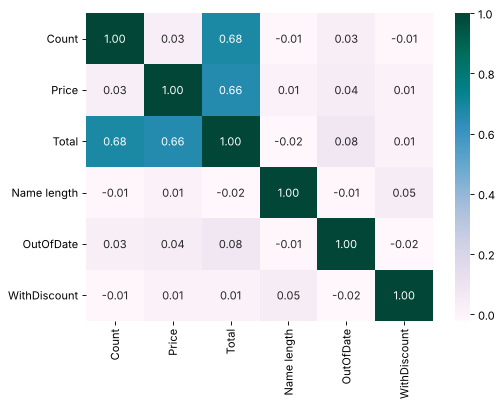

In [27]:
plt.figure(figsize=(7, 5))
sns.heatmap(cdata.corr(), cmap=plt.cm.PuBuGn, annot=True, fmt='.2f');

Из карты heatmap видно, что сильно коррелирует только производный признак `Total` - с `Count` (0.68) и `Price` (0.66), из которых он вычислен. Остальные коэффициенты близки к нулю. В частности, цена не связана с количеством, а просрочка и скидка не зависят от цены. Признак, линейно выражаемый через другие, несёт избыточную информацию, поэтому его можно удалить.

In [28]:
del_feats = ['Total']
data_uncorr = cdata.drop(del_feats, axis=1)
data_uncorr.columns

Index(['Count', 'Price', 'Name length', 'OutOfDate', 'WithDiscount'], dtype='str')

Перестраиваем heatmap без коррелирующих признаков

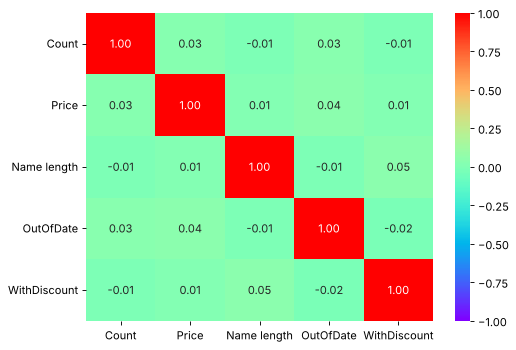

In [29]:
plt.figure(figsize=(7, 5))
sns.heatmap(data_uncorr.corr(), cmap=plt.cm.rainbow, annot=True, fmt='.2f', vmin=-1, vmax=1);

### Выводы
1. Набор содержит 1000 товаров. После предобработки (перевод цены в число, обработка пропусков) пригоден для анализа.
2. Количество и цена распределены почти равномерно, выбросов нет. Категории сбалансированы по численности и по ценам.
3. Значимых линейных зависимостей между исходными признаками нет (|r| < 0.05). Сильная корреляция `Total` с `Count` и `Price` объясняется тем, что `Total` - их произведение. Такой признак при построении моделей следует исключать.
4. Пропуски в признаках `OutOfDate` (166) и `WithDiscount` (254) нужно учитывать отдельно: их нельзя приравнивать к значению «Нет».

## Контрольные вопросы

**1. Какие библиотеки Python используются для построения графиков?**

* **matplotlib** - базовая библиотека; на ней основаны многие другие (модуль `pyplot`);
* **seaborn** - надстройка над matplotlib для статистической визуализации (`boxplot`, `pairplot`, `heatmap`, `countplot`), тесно интегрирована с pandas;
* **pandas** - методы `DataFrame.plot()`, `hist()`, `boxplot()` (внутри используют matplotlib);
* **plotly**, **bokeh**, **altair** - интерактивные графики для браузера и дашбордов.

**2. Опишите основные типы графиков. Приведите наименование функций, с использованием которых создаются графики.**

| Тип графика | Назначение | Функции |
|---|---|---|
| Линейный | изменение величины, зависимость y(x) | `plt.plot()`, `df.plot()`, `sns.lineplot()` |
| Точечная диаграмма | связь двух количественных признаков | `plt.scatter()`, `sns.scatterplot()` |
| Гистограмма | распределение количественного признака | `plt.hist()`, `df.hist()`, `sns.histplot()` |
| Столбчатая диаграмма | сравнение величин по категориям | `plt.bar()`, `plt.barh()`, `sns.countplot()`, `sns.barplot()` |
| Ящик с усами | медиана, квартили, выбросы | `plt.boxplot()`, `sns.boxplot()` |
| Скрипичная диаграмма | распределение + плотность | `sns.violinplot()` |
| Круговая диаграмма | доли от целого | `plt.pie()` |
| Тепловая карта | матрицы, корреляции | `sns.heatmap()`, `plt.imshow()` |
| Попарные распределения | все пары признаков сразу | `sns.pairplot()` |

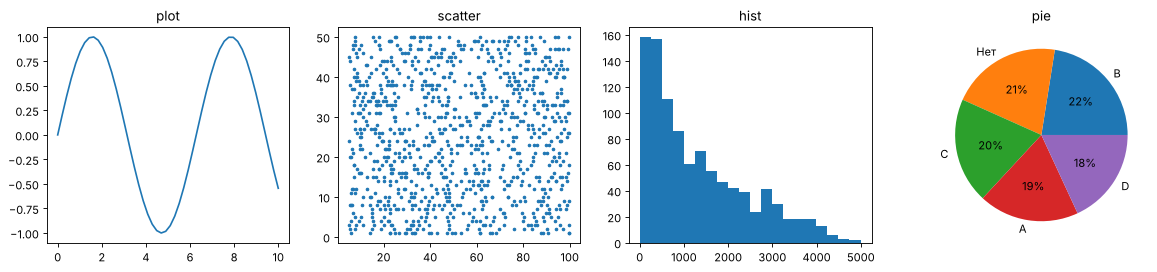

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
x = np.linspace(0, 10, 50)
axes[0].plot(x, np.sin(x))
axes[0].set_title('plot')
axes[1].scatter(data['Price'], data['Count'], s=5)
axes[1].set_title('scatter')
axes[2].hist(data['Total'], bins=20)
axes[2].set_title('hist')
axes[3].pie(data['Category'].value_counts(), labels=data['Category'].value_counts().index,
            autopct='%1.0f%%')
axes[3].set_title('pie')
plt.show()

**3. Поясните назначение метода `scatter()`.**

`plt.scatter(x, y)` строит точечную диаграмму (диаграмму рассеяния): каждый объект - точка с координатами (x, y). Используется для визуального поиска связи между двумя количественными признаками, кластеров и выбросов. Основные параметры: `s` - размер точек, `c`/`color` - цвет (можно передать массив значений), `edgecolors` - цвет границы, `alpha` - прозрачность, `marker` - форма, `label` - подпись для легенды.

**4. Поясните назначение метода `corr()`.**

`DataFrame.corr()` вычисляет матрицу попарных коэффициентов корреляции между числовыми столбцами. По умолчанию это коэффициент Пирсона (`method='pearson'`), есть также `'spearman'` и `'kendall'`. Значение от −1 до 1: около 0 - линейной связи нет, близко к ±1 - сильная прямая или обратная связь. Применяется для поиска зависимостей и избыточных (дублирующих) признаков.

In [31]:
data[['Count', 'Price', 'Total']].corr(method='spearman').round(3)

,Count,Price,Total
Count,1.000,0.029,0.715
Price,0.029,1.000,0.654
Total,0.715,0.654,1.000


**5. Поясните назначение метода `hist()`.**

`hist()` строит гистограмму: диапазон значений делится на интервалы (`bins`), над каждым рисуется столбец, высота которого - число попавших в интервал значений. Показывает форму распределения: равномерное, нормальное, скошенное, многомодальное. `plt.hist(x, bins=...)` строит одну гистограмму. `DataFrame.hist()` строит по гистограмме для каждого числового столбца (параметры `figsize`, `bins`, `sharex/sharey`, `layout`).

**6. Поясните назначение библиотеки pandas.**

pandas - библиотека для обработки и анализа табличных данных. Основные структуры - `Series` (одномерный размеченный массив) и `DataFrame` (таблица). Возможности: чтение и запись CSV, Excel, JSON, SQL; выборка и фильтрация; обработка пропусков (`isna`, `fillna`, `dropna`); группировка и агрегирование (`groupby`); объединение таблиц (`merge`, `concat`); сводные таблицы; работа с датами; быстрая визуализация. В этой работе с её помощью выполнены загрузка, очистка и группировка данных.

**7. Поясните назначение методов `head()` и `tail()` класса DataFrame.**

`head(n=5)` возвращает первые `n` строк таблицы, `tail(n=5)` - последние `n` строк. Используются для быстрого просмотра структуры данных и проверки результата загрузки или преобразований без вывода всей таблицы.

In [32]:
data[['ID', 'Name', 'Price']].tail(3)

,ID,Name,Price
997,998,Muffin Batt - Blueberry Passion,23.03
998,999,"Pasta - Canelloni, Single Serve",48.26
999,1000,Truffle Cups Green,75.14


**8. Для чего предназначен тип DataFrame библиотеки pandas?**

`DataFrame` - двумерная таблица с подписанными строками (индекс) и столбцами, где каждый столбец может иметь свой тип данных. Это основной объект для хранения и обработки набора данных: каждая строка - объект (товар), каждый столбец - признак (цена, количество). Поддерживает векторные операции над столбцами, выборку по условиям (`data[data['Price'] > 90]`), группировку, сортировку и построение графиков.

**9. Для чего предназначены методы `info()` и `describe()` класса DataFrame?**

* `info()` выводит сводку о структуре таблицы: число строк, названия и типы столбцов, количество непустых значений в каждом столбце, объём памяти. Помогает обнаружить пропуски и неправильные типы (например, цену-строку из-за `$`).
* `describe()` вычисляет описательные статистики: для числовых столбцов - `count`, `mean`, `std`, `min`, квартили 25/50/75 %, `max`. С параметром `include='object'` - число уникальных значений, самое частое значение и его частоту.

In [33]:
data[['Category', 'OutOfDate', 'WithDiscount']].describe()

,Category,OutOfDate,WithDiscount
count,1000,1000,1000
unique,5,3,3
top,B,Да,Да
freq,225,421,374


**10. Поясните назначение метода `heatmap()` библиотеки seaborn.**

`sns.heatmap(матрица)` отображает двумерную матрицу в виде цветных ячеек: цвет кодирует величину значения. Чаще всего применяется для визуализации корреляционной матрицы, где сильные связи сразу видны по цвету. Параметры: `cmap` - цветовая карта, `annot=True` - подписи значений в ячейках, `fmt` - формат подписей, `vmin`/`vmax` - границы шкалы, `linewidths` - линии между ячейками.

**11. Поясните методы установки размера графика.**

* `plt.figure(figsize=(ширина, высота))` - размер новой фигуры в дюймах;
* `fig, ax = plt.subplots(figsize=(w, h))` - то же при создании фигуры с осями;
* параметр `figsize` у методов pandas: `df.hist(figsize=(10, 6))`, `df.plot(figsize=...)`;
* `fig.set_size_inches(w, h)` - изменение размера существующей фигуры;
* `plt.rcParams['figure.figsize'] = (w, h)` - размер по умолчанию для всех графиков;
* у seaborn для фигурных функций - `height` и `aspect`: `sns.pairplot(..., height=2.5)`;
* `dpi` - плотность точек, влияет на размер в пикселях.

**12. Опишите функции, с использованием которых можно решить следующие задачи: установить шрифт для осей графика, установить подписи осей графика, установить текст легенды графика.**

* Подписи осей: `plt.xlabel('текст')`, `plt.ylabel('текст')` или `ax.set_xlabel()`, `ax.set_ylabel()`; заголовок - `plt.title()` / `ax.set_title()`.
* Шрифт: параметры `fontsize`, `fontfamily`, `fontweight` у этих функций; шрифт делений осей - `plt.xticks(fontsize=..., rotation=...)`, `ax.tick_params(axis='x', labelsize=...)`; глобально - `plt.rcParams['font.family']`, `plt.rcParams['font.size']`.
* Легенда: текст задаётся параметром `label=` при построении графика, затем вызывается `plt.legend()`. Можно передать подписи напрямую: `plt.legend(['A', 'B'], title='...', loc='upper left', fontsize=...)`.

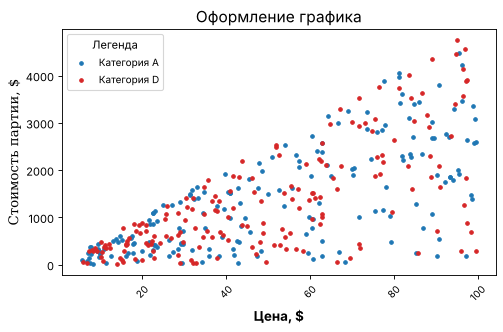

In [34]:
plt.figure(figsize=(7, 4))
for cat, color in [('A', 'tab:blue'), ('D', 'tab:red')]:
    subset = data[data['Category'] == cat]
    plt.scatter(subset['Price'], subset['Total'], s=10, color=color, label=f'Категория {cat}')
plt.xlabel('Цена, $', fontsize=12, fontweight='bold')
plt.ylabel('Стоимость партии, $', fontsize=12, fontfamily='serif')
plt.xticks(fontsize=9, rotation=45)
plt.title('Оформление графика', fontsize=14)
plt.legend(title='Легенда', loc='upper left', fontsize=9);